# 07 — Đánh giá KNN đã khóa trên test

Dùng đúng HSV12 và cấu hình trong `selection/locked_knn_config.json`. Không tìm lại k, trọng số hoặc khoảng cách trên test; không gộp train+dev. Train có 12.494 ảnh, test dự kiến 1.553 ảnh.

Test của dự án đã được đánh giá và xem trong các thử nghiệm trước. Vì vậy, đây là đánh giá cấu hình mới đã khóa trên split test hiện có, không phải một holdout hoàn toàn chưa xem. Sau bước này, các lỗi test dùng để mô tả hạn chế, không dùng để chọn lại cấu hình trong thí nghiệm này.

In [1]:
import json
import hashlib
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import read_rgb224
from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"
RESULTS_ROOT = PROJECT_ROOT / "src" / "KNN" / "results_224"
lock_file = RESULTS_ROOT / "selection" / "locked_knn_config.json"
config = json.loads(lock_file.read_text(encoding="utf-8"))
output_dir = RESULTS_ROOT / "test_final"

## 1. Kiểm tra cấu hình và các file đã khóa

Đối chiếu SHA-256 trước khi đánh giá. Nếu đầu vào khác lúc khóa, notebook dừng để xác minh, không tự thay cấu hình. Notebook này chỉ triển khai HSV12, là phương án đã thắng trên dev.

In [2]:
def file_hash(path):
    with path.open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()


changed_files = []
for relative_path, expected_hash in config["sha256"].items():
    path = PROJECT_ROOT / relative_path
    if not path.is_file() or file_hash(path) != expected_hash:
        changed_files.append(relative_path)

if changed_files:
    sys.exit("File đã thay đổi hoặc bị thiếu. Kiểm tra trước khi chạy test: " + str(changed_files))
if config["feature_id"] != "HSV12":
    sys.exit("Notebook này chỉ dành cho cấu hình HSV12 đã khóa.")

print("Các file đã khóa: khớp")
print("Feature:", config["feature_id"], "| số chiều:", config["feature_dim"])
print("KNN:", config["knn"])

Các file đã khóa: khớp
Feature: HSV12 | số chiều: 1728
KNN: {'n_neighbors': 1, 'weights': 'uniform', 'metric': 'euclidean', 'algorithm': 'brute'}


## 2. Đọc train đã có và lập danh sách test

Feature train được lấy từ cache đã khóa. Test chỉ gồm sáu mệnh giá của bài toán, sắp theo mệnh giá tăng dần rồi tên file. Nhãn là giá trị VND thật, không phải chỉ số 0–5.

In [3]:
feature_dir = PROJECT_ROOT / config["feature_folder"]
X_train = np.load(feature_dir / "X_train.npy", mmap_mode="r")
y_train = np.load(feature_dir / "y_train.npy")
labels = config["classes_vnd"]

rows = []
for label in labels:
    for path in sorted((DATA_ROOT / "test" / str(label)).glob("*.png")):
        rows.append({
            "relative_path": path.relative_to(DATA_ROOT).as_posix(),
            "label_vnd": label,
        })

test_manifest = pd.DataFrame(rows)
y_test = test_manifest["label_vnd"].to_numpy(dtype=np.int64)
if len(test_manifest) != config["experiment_protocol"]["splits"]["test"]:
    sys.exit("Số ảnh test khác quy mô đã chốt. Kiểm tra DATA trước khi tiếp tục.")

print("Train:", X_train.shape, y_train.shape)
print("Số ảnh test:", len(test_manifest))

Train: (12494, 1728) (12494,)
Số ảnh test: 1553


## 3. Trích HSV12 cho test

Giữ nguyên pipeline của train/dev: RGB → resize trực tiếp 224×224 bằng INTER_LINEAR → HSV → histogram chung ba kênh với 12×12×12 bin → L2. Histogram không giữ vị trí chữ số hoặc họa tiết.

Đọc từng ảnh, trích feature rồi chuyển sang ảnh tiếp theo; không giữ toàn bộ ảnh RGB trong RAM. Không học hoặc fit phép biến đổi nào trên test.

In [4]:
HSV_BINS = config["experiment_protocol"]["hsv"]["bins"]
HSV_RANGES = config["experiment_protocol"]["hsv"]["ranges"]


def extract_hsv_histogram(image):
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist(
        [hsv_image], [0, 1, 2], None,
        HSV_BINS, HSV_RANGES
    )
    return cv2.normalize(hist, hist).flatten()


start = perf_counter()
X_test = np.empty((len(test_manifest), config["feature_dim"]), dtype=np.float32)
for i, relative_path in enumerate(test_manifest["relative_path"]):
    image = read_rgb224(DATA_ROOT / relative_path)
    X_test[i] = extract_hsv_histogram(image)
    del image
feature_seconds = perf_counter() - start

print("Test feature:", X_test.shape, X_test.dtype)
print("Thời gian trích feature (giây):", round(feature_seconds, 3))

Test feature: (1553, 1728) float32
Thời gian trích feature (giây): 11.706


## 4. Dự đoán với đúng một cấu hình

KNN ghi nhớ feature train; `fit` không phải huấn luyện mạng neural. Chỉ fit trên train và dự đoán test với cấu hình đã khóa. Thời gian predict đo cả lô test trên máy hiện tại, chưa bao gồm đọc ảnh/trích feature và không phải độ trễ từng ảnh khi triển khai.

In [5]:
knn = KNeighborsClassifier(**config["knn"])
start = perf_counter()
knn.fit(X_train, y_train)
fit_seconds = perf_counter() - start

start = perf_counter()
y_test_pred = knn.predict(X_test)
predict_seconds = perf_counter() - start

scores = evaluate_classification(y_test, y_test_pred)
summary = pd.DataFrame([{
    "feature": config["feature_id"], "feature_dim": config["feature_dim"],
    "k": config["knn"]["n_neighbors"], "weights": config["knn"]["weights"],
    "metric": config["knn"]["metric"], "n_test": len(y_test),
    "accuracy": scores["accuracy"], "macro_f1": scores["macro_f1"],
    "mae_vnd": scores["mae_vnd"],
}])
display(summary)
print("Số ảnh đúng:", int(np.trace(scores["confusion_matrix"])), "/", len(y_test))
print("Thời gian predict cả lô (giây):", round(predict_seconds, 3))

,feature,feature_dim,k,weights,metric,n_test,accuracy,macro_f1,mae_vnd
0,HSV12,1728,1,uniform,euclidean,1553,0.764327,0.76871,53947.19897


Số ảnh đúng: 1187 / 1553
Thời gian predict cả lô (giây): 3.645


## 5. Ma trận nhầm lẫn và kết quả từng lớp

Hàng là mệnh giá thật, cột là mệnh giá dự đoán. Đường chéo chứa các dự đoán đúng. MAE là chênh lệch mệnh giá tuyệt đối trung bình trên **toàn bộ test**, bao gồm ảnh đúng có sai lệch 0; không đồng nghĩa với thiệt hại tài chính thực tế.

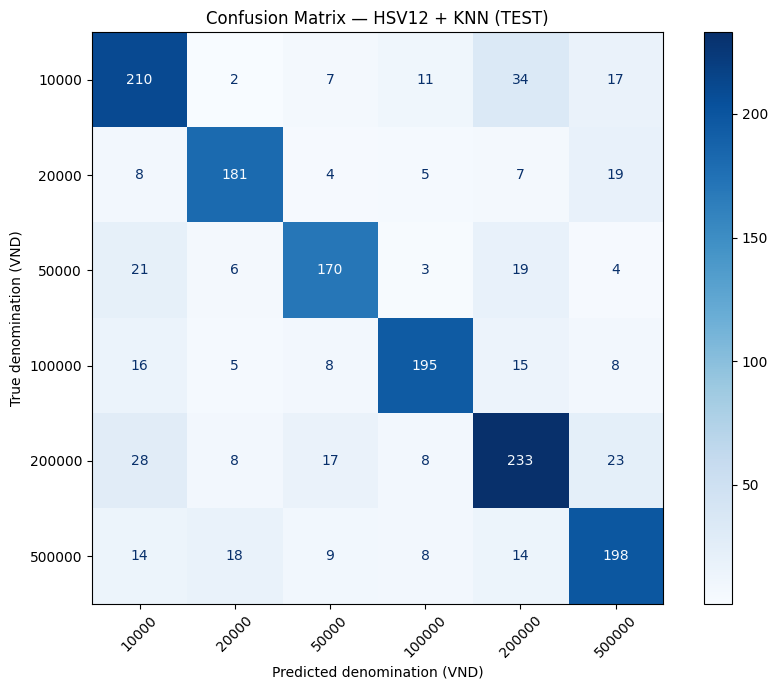

,denomination_vnd,support,precision,recall,f1
0,10000,281,0.707071,0.747331,0.726644
1,20000,224,0.822727,0.808036,0.815315
2,50000,223,0.790698,0.762332,0.776256
3,100000,247,0.847826,0.789474,0.817610
4,200000,317,0.723602,0.735016,0.729264
5,500000,261,0.736059,0.758621,0.747170


In [6]:
output_dir.mkdir(parents=True, exist_ok=True)
cm = np.asarray(scores["confusion_matrix"])
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", values_format="d", xticks_rotation=45
)
ax.set_title("Confusion Matrix — HSV12 + KNN (TEST)")
ax.set_xlabel("Predicted denomination (VND)")
ax.set_ylabel("True denomination (VND)")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix_test.png", dpi=180)
plt.show()

per_class = pd.DataFrame(scores["per_class"])
display(per_class[["denomination_vnd", "support", "precision", "recall", "f1"]])

## 6. Xem các cặp lỗi và lưu kết quả

Một bảng xếp theo số lần nhầm, một bảng xếp theo tổng chênh lệch VND. Chúng trả lời hai câu hỏi khác nhau: lỗi nào hay gặp và cặp lỗi nào đóng góp nhiều vào MAE.

Lưu toàn bộ dự đoán cùng đường dẫn ảnh để notebook phân tích lỗi đọc lại; không dự đoán thêm hoặc thay tham số khi xem lỗi.

In [7]:
error_pairs = pd.DataFrame(scores["error_pairs"], columns=[
    "true_vnd", "predicted_vnd", "count", "gap_vnd", "total_gap_vnd"
])
print("Các cặp lỗi xuất hiện nhiều nhất:")
display(error_pairs.sort_values("count", ascending=False, kind="stable").head(5))
print("Các cặp lỗi đóng góp tổng chênh lệch lớn nhất:")
display(error_pairs.sort_values("total_gap_vnd", ascending=False, kind="stable").head(5))

predictions = test_manifest[["relative_path"]].copy()
predictions["y_true_vnd"] = y_test
predictions["y_pred_vnd"] = y_test_pred
predictions["correct"] = y_test == y_test_pred
predictions["gap_vnd"] = np.abs(y_test - y_test_pred)

summary.to_csv(output_dir / "summary_test.csv", index=False)
predictions.to_csv(output_dir / "predictions_test.csv", index=False)
test_manifest.to_csv(output_dir / "test_manifest.csv", index=False)
per_class.to_csv(output_dir / "per_class_test.csv", index=False)
error_pairs.to_csv(output_dir / "error_pairs_test.csv", index=False)
pd.DataFrame(cm, index=labels, columns=labels).to_csv(output_dir / "confusion_matrix_test.csv")
np.save(output_dir / "X_test.npy", X_test)
(output_dir / "metrics_test.json").write_text(json.dumps(scores, indent=2), encoding="utf-8")
(output_dir / "locked_knn_config_used.json").write_bytes(lock_file.read_bytes())

run_info = {
    "lock_sha256": file_hash(lock_file),
    "preprocessing_code_sha256": file_hash(PROJECT_ROOT / "src" / "preprocessing.py"),
    "metrics_code_sha256": file_hash(PROJECT_ROOT / "src" / "evaluation" / "value_metrics.py"),
    "feature_seconds": feature_seconds, "fit_seconds": fit_seconds,
    "predict_seconds": predict_seconds,
    "train_samples": len(y_train), "test_samples": len(y_test),
    "test_used_for_tuning": False,
}
(output_dir / "run_info.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")
print("Đã lưu kết quả tại:", output_dir)

Các cặp lỗi xuất hiện nhiều nhất:


,true_vnd,predicted_vnd,count,gap_vnd,total_gap_vnd
3,10000,200000,34,190000,6460000
20,200000,10000,28,190000,5320000
24,200000,500000,23,300000,6900000
10,50000,10000,21,40000,840000
9,20000,500000,19,480000,9120000


Các cặp lỗi đóng góp tổng chênh lệch lớn nhất:


,true_vnd,predicted_vnd,count,gap_vnd,total_gap_vnd
9,20000,500000,19,480000,9120000
26,500000,20000,18,480000,8640000
4,10000,500000,17,490000,8330000
24,200000,500000,23,300000,6900000
25,500000,10000,14,490000,6860000


Đã lưu kết quả tại: C:\CS231\src\KNN\results_224\test_final


## Sau khi chạy

Gửi kết quả để kiểm tra trước khi chuyển sang phân tích lỗi bằng ảnh thật. Không điều chỉnh cấu hình đã khóa dựa trên các bảng test. Chạy lại notebook sẽ ghi đè các output trong `test_final`; kết quả dev, file khóa và DATA không bị sửa.